## Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import sys, time, warnings
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

from data import load_instance
from evaluate import evaluate, timetable_table, W_B2B, W_SAMEDAY, W_ROOM
from cpsat_solver import solve_cpsat, min_same_day_pairs
from ga_solver import solve_ga


RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
pd.set_option("display.width", 140)

# Experiment settings
CP_TIME_LIMIT = 120          # seconds, full instance
CP_TIME_LIMIT_SCALE = 60     # seconds, each scalability instance
GA_PARAMS = dict(pop_size=200, n_gen=400, cxpb=0.8, mutpb=0.3, indpb=0.05)
GA_SEEDS = range(10)         # independent GA runs on the full instance
SCALE_SIZES = [6, 10, 14, 18, 22]
SCALE_SEEDS = range(5)

## 1. Data exploration

Only `schedule.csv` (who takes which course) and `classrooms.csv` (room capacities) drive the model.
The existing `classroom_id`/`timeslot_id` columns in `schedule.csv` are the teaching timetable, not exams, so we ignore them.

In [2]:
raw = {f: pd.read_csv(f"data/{f}.csv") for f in
       ["schedule", "courses", "classrooms", "timeslots", "students", "instructors"]}
display(pd.DataFrame({"rows": {k: len(v) for k, v in raw.items()}}).T)

inst = load_instance("data")
enrol = raw["schedule"][["student_id", "course_id"]].drop_duplicates()
per_student = enrol.groupby("student_id").size()
n_pairs = inst.n_exams * (inst.n_exams - 1) // 2
shared = [s for *_, s in inst.conflict_pairs()]

print(f"Exams (one per course)      : {inst.n_exams}")
print(f"Students with enrolments    : {enrol.student_id.nunique()}  (exams per student: "
      f"min {per_student.min()}, mean {per_student.mean():.2f}, max {per_student.max()})")
print(f"Students per exam           : min {inst.size.min()}, mean {inst.size.mean():.0f}, max {inst.size.max()}")
print(f"Rooms                       : {inst.n_rooms}, capacity {inst.room_cap.min()}-{inst.room_cap.max()}, "
      f"total seats {inst.room_cap.sum()}")
print(f"Conflicting exam pairs      : {len(shared)} of {n_pairs}  "
      f"(shared students per pair: {min(shared)}-{max(shared)})")

ts = raw["timeslots"]
bad = (ts.end_time <= ts.start_time).sum()
print(f"timeslots.csv rows with end <= start: {bad} of {len(ts)}  -> not usable as exam periods")

,schedule,courses,classrooms,timeslots,students,instructors
rows,9082,22,30,100,3000,50


Exams (one per course)      : 22
Students with enrolments    : 3000  (exams per student: min 1, mean 3.03, max 5)
Students per exam           : min 376, mean 413, max 457
Rooms                       : 30, capacity 21-46, total seats 1004
Conflicting exam pairs      : 231 of 231  (shared students per pair: 30-79)
timeslots.csv rows with end <= start: 44 of 100  -> not usable as exam periods


**Key observations that shape the model**

1. **Every pair of courses shares students** (the conflict graph is complete). So no two exams can ever be in the
   same period → we need at least 22 periods (the chromatic number of the conflict graph is 22).
2. **Every exam is larger than the largest room** (~400 students vs ≤ 46 seats), so an exam must be split over
   several rooms in the same period. Total seating (1004) fits one exam per period comfortably.
3. `timeslots.csv` is inconsistent (many slots end before they start), so we build a clean grid instead:
   **10 exam days (two Mon–Fri weeks) × 3 sessions (09:00, 13:00, 16:00) = 30 periods.**
   With 22 exams on 10 days, some days must hold 2–3 exams, so the soft constraint is genuinely in tension.

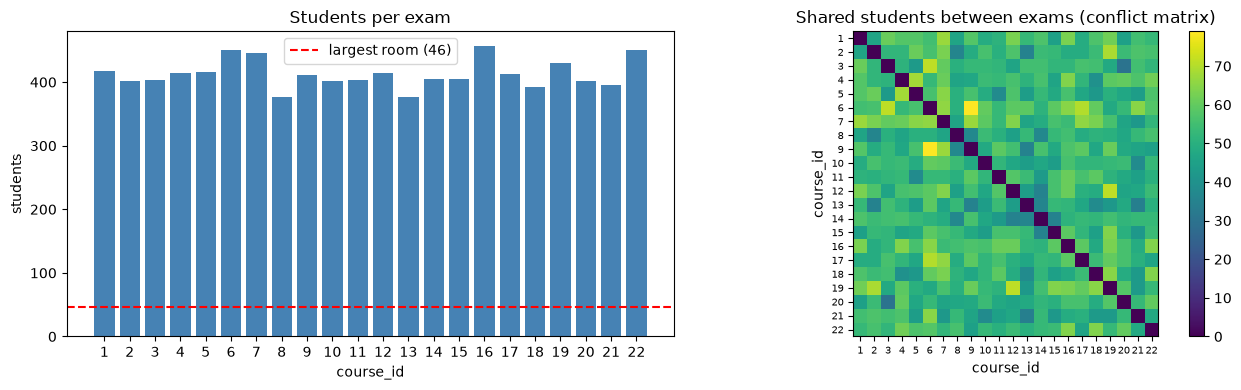

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].bar([str(c) for c in inst.exam_ids], inst.size, color="steelblue")
ax[0].axhline(inst.room_cap.max(), color="red", ls="--", label=f"largest room ({inst.room_cap.max()})")
ax[0].set(title="Students per exam", xlabel="course_id", ylabel="students"); ax[0].legend()

im = ax[1].imshow(inst.conflict, cmap="viridis")

ax[1].set(title="Shared students between exams (conflict matrix)", xlabel="course_id", ylabel="course_id",
          xticks=range(inst.n_exams), yticks=range(inst.n_exams))
ax[1].set_xticklabels(inst.exam_ids, fontsize=7); ax[1].set_yticklabels(inst.exam_ids, fontsize=7)

plt.colorbar(im, ax=ax[1]); plt.tight_layout()
plt.savefig(RESULTS / "data_overview.png", dpi=120); plt.show()

## 2. Mathematical formulation

**Sets.** Exams $E$; days $D$; sessions per day $S=3$; periods $P=\{0,\dots,|D|S-1\}$ with day$(p)=\lfloor p/S \rfloor$;
rooms $R$.
**Parameters.** $n_e$ students in exam $e$; $c_r$ capacity of room $r$; $s_{ij}$ students taking both $i$ and $j$.
Weights $w_{b2b}=3$, $w_{day}=1$, $w_{room}=10$.

**Decision variables (all binary).**

| variable | meaning |
|---|---|
| $x_{ep}$ | exam $e$ is held in period $p$ |
| $z_{ed}$ | exam $e$ is held on day $d$ (= $\sum_{s} x_{e,dS+s}$) |
| $y_{er}$ | room $r$ is used for exam $e$ |
| $sd_{ij}$ | exams $i,j$ (with $s_{ij}>0$) are on the same day |
| $adj_{ij}$ | exams $i,j$ are in consecutive sessions of the same day |

**Objective.**
$$\min \; \sum_{i<j} s_{ij}\big(w_{day}\, sd_{ij} + (w_{b2b}-w_{day})\, adj_{ij}\big) \;+\; w_{room}\sum_{e,r} y_{er}$$
(a same-day pair costs 1 per shared student; a back-to-back pair costs 3).

**Constraints.**

$$
\begin{aligned}
&\textstyle\sum_{p} x_{ep} = 1 && \forall e && \text{(each exam once)}\\
&x_{ip} + x_{jp} \le 1 && \forall p,\ \forall i<j: s_{ij}>0 && \text{(H1 no student clash)}\\
&x_{ip} + x_{jp} + y_{ir} + y_{jr} \le 3 && \forall p, r,\ \forall i<j: s_{ij}=0 && \text{(H2 no room clash)}\\
&\textstyle\sum_r c_r\, y_{er} \ge n_e && \forall e && \text{(H3 capacity)}\\
&z_{id} + z_{jd} - 1 \le sd_{ij} && \forall d,\ i<j && \text{(same-day link)}\\
&x_{ip} + x_{j,p+1} - 1 \le adj_{ij},\ \ x_{jp} + x_{i,p+1} - 1 \le adj_{ij} && \forall p,p+1 \text{ on the same day} && \text{(back-to-back link)}
\end{aligned}
$$

**Extra constraints that do not change the optimum but help the solver.**
* Symmetry breaking: days are interchangeable, so exam 0 is fixed on day 0.
* Implied bound: 22 exams over 10 days force at least 14 same-day pairs and 4 back-to-back pairs
  ($\sum sd \ge 14$, $\sum adj \ge 4$). This lifts CP-SAT's lower bound from ~2230 to ~3000.

**Complexity.** With rooms ignored this is graph colouring with a quadratic (QAP-like) penalty — NP-hard.

## 3. Exact method — CP-SAT

CP-SAT combines SAT-style clause learning, LP relaxations and large-neighbourhood search. It returns a solution
plus a **proven lower bound**, so we always know how far from optimal we are (the *gap*).

In [4]:
cp = solve_cpsat(inst, time_limit=CP_TIME_LIMIT)
cp_ev = evaluate(inst, cp["period"], cp["rooms"])

print(f"Status     : {cp['status']}")
print(f"Objective  : {cp['objective']:.0f}   (proximity {cp_ev['proximity']} + {W_ROOM} x {cp_ev['rooms_used']} rooms)")
print(f"Lower bound: {cp['best_bound']:.0f}   gap {cp['gap_pct']:.2f}%")
print(f"Runtime    : {cp['runtime_s']:.1f}s")
print(f"Feasible   : {cp_ev['feasible']}  (student clashes {cp_ev['student_clashes']}, "
      f"room clashes {cp_ev['room_clashes']}, seat shortfall {cp_ev['seat_shortfall']})")

tt_cp = pd.DataFrame(timetable_table(inst, cp["period"], cp["rooms"]))
tt_cp.to_csv(RESULTS / "timetable_cpsat.csv", index=False)
display(tt_cp)

Status     : FEASIBLE
Objective  : 3095   (proximity 865 + 10 x 223 rooms)
Lower bound: 3002   gap 3.00%
Runtime    : 120.1s
Feasible   : True  (student clashes 0, room clashes 0, seat shortfall 0)


,period,course_id,course,students,rooms,seats,room_ids
0,Week 1 Mon 09:00,1,Expanded web-enabled core,418,10,418,"3,7,9,15,16,19,22,27,29,30"
1,Week 1 Mon 16:00,2,Cross-group tertiary algorithm,402,10,402,"3,9,10,16,19,22,27,28,29,30"
2,Week 1 Tue 09:00,11,Business-focused executive encryption,403,10,403,"3,7,9,16,19,22,27,28,29,30"
3,Week 1 Tue 16:00,5,Visionary leadingedge alliance,416,10,416,"3,7,8,9,10,16,25,27,29,30"
4,Week 1 Wed 09:00,3,Synergized secondary throughput,404,10,404,"3,7,9,16,17,22,27,28,29,30"
5,Week 1 Wed 16:00,20,Mandatory impactful artificial intelligence,402,10,402,"3,9,10,16,19,22,27,28,29,30"
6,Week 1 Thu 09:00,8,Organized background forecast,377,9,377,"3,9,10,16,19,22,27,29,30"
7,Week 1 Thu 16:00,9,De-engineered optimizing complexity,411,10,411,"3,7,9,10,15,16,27,28,29,30"
8,Week 1 Fri 09:00,10,Diverse zero-defect protocol,402,10,402,"3,9,10,16,19,22,27,28,29,30"
9,Week 1 Fri 13:00,21,Advanced maximized productivity,395,10,395,"3,9,10,16,22,25,27,28,29,30"


## 4. Heuristic method — Genetic Algorithm (DEAP)

* **Chromosome:** a permutation of the 30 period indices; exam $e$ goes to period `ind[e]`.
  All exams get different periods, so **H1 can never be violated** (and, since every pair clashes, this loses nothing).
* **Decoder:** for each exam, open the largest rooms until everyone is seated (fewest rooms → H2/H3 always satisfied).
* **Fitness:** the same objective as CP-SAT (computed in `evaluate.py`), plus a large penalty for any hard violation.
* **Operators:** ordered crossover (OX), swap mutation, tournament selection (k = 3), elitism (Hall of Fame).

In [ ]:
ga_runs = [solve_ga(inst, seed=s, **GA_PARAMS) for s in GA_SEEDS]
rows = []

for r in ga_runs:
    ev = evaluate(inst, r["period"], r["rooms"])
    rows.append({"seed": r["seed"], "objective": r["objective"], "proximity": ev["proximity"],
                 "rooms_used": ev["rooms_used"], "feasible": ev["feasible"], "runtime_s": round(r["runtime_s"], 1)})
    
ga_df = pd.DataFrame(rows)
ga_df.to_csv(RESULTS / "ga_runs.csv", index=False)
display(ga_df)

ga_best = min(ga_runs, key=lambda r: r["objective"])
tt_ga = pd.DataFrame(timetable_table(inst, ga_best["period"], ga_best["rooms"]))
tt_ga.to_csv(RESULTS / "timetable_ga.csv", index=False)

## 5. Comparison on the full instance (22 exams, 30 periods, 30 rooms)

In [ ]:
cmp = pd.DataFrame([
    {"method": "CP-SAT", "best": cp["objective"], "mean": cp["objective"], "std": 0.0,
     "best proximity": cp_ev["proximity"], "rooms": cp_ev["rooms_used"],
     "gap to CP bound %": round(cp["gap_pct"], 2), "runtime_s": round(cp["runtime_s"], 1),
     "feasible": cp_ev["feasible"], "optimality proof": cp["status"] == "OPTIMAL"},
    {"method": f"GA ({len(ga_runs)} runs)", "best": ga_df.objective.min(), "mean": round(ga_df.objective.mean(), 1),
     "std": round(ga_df.objective.std(), 1), "best proximity": ga_df.proximity.min(), "rooms": ga_df.rooms_used.min(),
     "gap to CP bound %": round(100 * (ga_df.objective.min() - cp["best_bound"]) / ga_df.objective.min(), 2),
     "runtime_s": round(ga_df.runtime_s.mean(), 1), "feasible": ga_df.feasible.all(), "optimality proof": False},
])
cmp.to_csv(RESULTS / "comparison_full.csv", index=False)
display(cmp)

,method,best,mean,std,best proximity,rooms,gap to CP bound %,runtime_s,feasible,optimality proof
0,CP-SAT,3099.0,3099.0,0.0,869,223,3.13,120.0,True,False
1,GA (10 runs),3090.0,3142.3,56.8,860,223,2.85,16.3,True,False


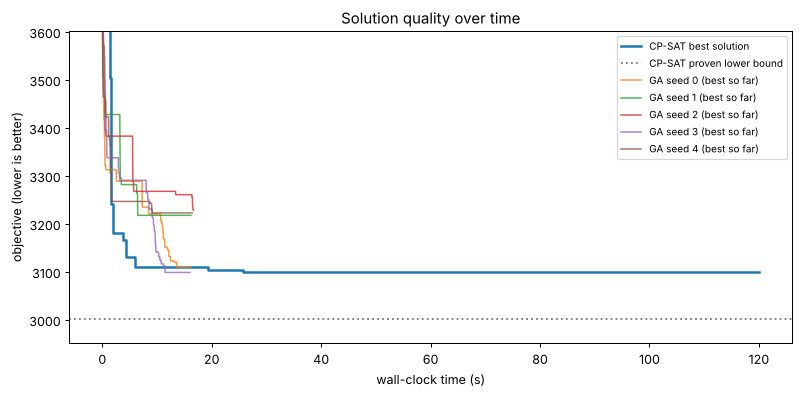

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
t, obj = zip(*cp["trace"])
ax.step(t + (cp["runtime_s"],), obj + (obj[-1],), where="post", label="CP-SAT best solution", lw=2)
ax.axhline(cp["best_bound"], color="grey", ls=":", label="CP-SAT proven lower bound")

for r in ga_runs[:5]:
    tg = np.linspace(0, r["runtime_s"], len(r["history"]))
    ax.plot(tg, np.minimum.accumulate(r["history"]), alpha=0.8, lw=1.2, label=f"GA seed {r['seed']} (best so far)")
    
ax.set(xlabel="wall-clock time (s)", ylabel="objective (lower is better)",
       title="Solution quality over time", ylim=(cp["best_bound"] - 50, cp["best_bound"] + 600))
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(RESULTS / "convergence.png", dpi=120); plt.show()

## 6. Scalability

Sub-instances with the first *k* courses (days = ⌈0.45·k⌉, so the period-to-exam ratio stays ≈ 1.35).
CP-SAT gets 60 s per instance; GA is run with 5 seeds.

In [ ]:
scale_rows = []
for k in SCALE_SIZES:
    sub = load_instance("data", n_exams=k)
    c = solve_cpsat(sub, time_limit=CP_TIME_LIMIT_SCALE)
    gs = [solve_ga(sub, seed=s, **GA_PARAMS) for s in SCALE_SEEDS]
    g_obj = [g["objective"] for g in gs]
    scale_rows.append({
        "exams": k, "periods": sub.n_periods,
        "cp_status": c["status"], "cp_obj": c["objective"], "cp_bound": c["best_bound"],
        "cp_gap_%": round(c["gap_pct"], 2), "cp_time_s": round(c["runtime_s"], 1),
        "ga_best": min(g_obj), "ga_mean": round(np.mean(g_obj), 1),
        "ga_vs_cp_%": round(100 * (np.mean(g_obj) - c["objective"]) / c["objective"], 2),
        "ga_time_s": round(np.mean([g["runtime_s"] for g in gs]), 1),
    })
    print(scale_rows[-1])
scale = pd.DataFrame(scale_rows)
scale.to_csv(RESULTS / "scalability.csv", index=False)
display(scale)

{'exams': 6, 'periods': 9, 'cp_status': 'OPTIMAL', 'cp_obj': 752.0, 'cp_bound': 752.0, 'cp_gap_%': 0.0, 'cp_time_s': 0.0, 'ga_best': 752.0, 'ga_mean': np.float64(752.0), 'ga_vs_cp_%': np.float64(0.0), 'ga_time_s': np.float64(6.5)}
{'exams': 10, 'periods': 15, 'cp_status': 'OPTIMAL', 'cp_obj': 1246.0, 'cp_bound': 1246.0, 'cp_gap_%': 0.0, 'cp_time_s': 0.5, 'ga_best': 1246.0, 'ga_mean': np.float64(1246.0), 'ga_vs_cp_%': np.float64(0.0), 'ga_time_s': np.float64(9.7)}
{'exams': 14, 'periods': 21, 'cp_status': 'OPTIMAL', 'cp_obj': 1704.0, 'cp_bound': 1704.0, 'cp_gap_%': 0.0, 'cp_time_s': 30.4, 'ga_best': 1706.0, 'ga_mean': np.float64(1706.6), 'ga_vs_cp_%': np.float64(0.15), 'ga_time_s': np.float64(12.1)}
{'exams': 18, 'periods': 27, 'cp_status': 'FEASIBLE', 'cp_obj': 2199.0, 'cp_bound': 2147.0, 'cp_gap_%': 2.36, 'cp_time_s': 60.0, 'ga_best': 2199.0, 'ga_mean': np.float64(2205.0), 'ga_vs_cp_%': np.float64(0.27), 'ga_time_s': np.float64(14.1)}
{'exams': 22, 'periods': 30, 'cp_status': 'FEASIBL

,exams,periods,cp_status,cp_obj,cp_bound,cp_gap_%,cp_time_s,ga_best,ga_mean,ga_vs_cp_%,ga_time_s
0,6,9,OPTIMAL,752.0,752.0,0.00,0.0,752.0,752.0,0.00,6.5
1,10,15,OPTIMAL,1246.0,1246.0,0.00,0.5,1246.0,1246.0,0.00,9.7
2,14,21,OPTIMAL,1704.0,1704.0,0.00,30.4,1706.0,1706.6,0.15,12.1
3,18,27,FEASIBLE,2199.0,2147.0,2.36,60.0,2199.0,2205.0,0.27,14.1
4,22,30,FEASIBLE,3095.0,3002.0,3.00,60.0,3099.0,3175.8,2.61,16.5


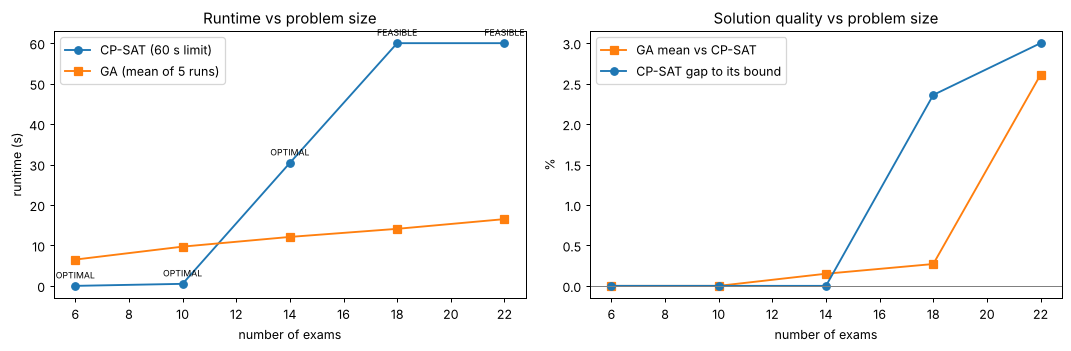

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(scale.exams, scale.cp_time_s, "o-", label="CP-SAT (60 s limit)")
ax[0].plot(scale.exams, scale.ga_time_s, "s-", label="GA (mean of 5 runs)")
for _, r in scale.iterrows():
    ax[0].annotate(r.cp_status, (r.exams, r.cp_time_s), textcoords="offset points", xytext=(0, 6), fontsize=7, ha="center")
ax[0].set(xlabel="number of exams", ylabel="runtime (s)", title="Runtime vs problem size"); ax[0].legend()
ax[1].plot(scale.exams, scale["ga_vs_cp_%"], "s-", color="tab:orange", label="GA mean vs CP-SAT")
ax[1].plot(scale.exams, scale["cp_gap_%"], "o-", color="tab:blue", label="CP-SAT gap to its bound")
ax[1].axhline(0, color="grey", lw=0.8)
ax[1].set(xlabel="number of exams", ylabel="%", title="Solution quality vs problem size"); ax[1].legend()
plt.tight_layout(); plt.savefig(RESULTS / "scalability.png", dpi=120); plt.show()

## 7. Feasibility — what if there are too few periods?

With 7 exam days (21 periods) the 22 mutually-conflicting exams cannot fit. CP-SAT **proves** infeasibility;
the GA cannot (its permutation encoding cannot even represent the instance, and a penalty-based GA would just
return its least-bad timetable without any proof).

In [ ]:
tight = load_instance("data", n_days=7)
r = solve_cpsat(tight, time_limit=30)
print(f"{tight.n_exams} exams, {tight.n_periods} periods -> CP-SAT status: {r['status']} in {r['runtime_s']:.2f}s")

22 exams, 21 periods -> CP-SAT status: INFEASIBLE in 0.29s


## 8. Discussion

_Numbers below are from our run. The GA is seeded, so it repeats exactly. CP-SAT runs 8 threads in parallel and
stops on a wall-clock limit, so its result can move by a few points between runs (we saw 3090–3118 on the full instance)._

**Feasibility.** Both methods always returned feasible timetables: no student clashes, no room clashes and every
exam fully seated (re-checked independently by `verify_results.py`). Only CP-SAT can *prove* that an instance has
no feasible timetable (Section 7: 22 exams in 21 periods was shown INFEASIBLE in under a second).

**Solution quality.**
* Small and medium instances (6, 10 and 14 exams): CP-SAT proved optimality in 0–30 s. The GA found the proven
  optimum in every run for 6 and 10 exams, and came within 0.15% for 14 exams.
* Large instances (18 and 22 exams): CP-SAT hits the time limit, with a remaining gap of about 2–3% to its own
  lower bound. On the full instance both methods land around 3090–3100 (best proximity 860 + 223 rooms). In this
  run the single best timetable (3090) came from a GA seed. CP-SAT reached 3099 in 120 s, and an earlier run
  reached 3090 too. So neither method is clearly better on quality at this size. The optimum lies in [3002, 3090].
* The GA's weakness is variance: the mean is ~1.7% worse than its best, and some seeds stall early around 3220
  (premature convergence, visible in the convergence plot). Several runs or a larger population are needed.
* The room term (223 rooms) is solved exactly by both methods. Taking the largest rooms first is optimal when an
  exam has the period to itself, so the methods differ only in how well they spread out students' exams.

**Runtime and scalability.** CP-SAT is near-instant up to 10 exams, but proving optimality grows quickly
(30 s at 14 exams, not proven within 60 s from 18). Most of the remaining gap comes from a weak lower bound
(proximity bound 772 vs 860 found), not from bad solutions: CP-SAT finds good timetables within ~10 s. GA runtime
grows almost linearly (6 s to 16 s) because it is driven by population × generations, not by a search tree.

**Trade-offs.** CP-SAT gives optimality proofs, a quality guarantee (the gap) and infeasibility proofs, but its proof
effort explodes with size. The GA is simple, predictable in runtime and easy to extend with new soft constraints,
but gives no guarantee, needs parameter tuning and multiple runs.

**Limitations.** The data is synthetic: every course shares students with every other course, so the colouring part
is trivial (one exam per period). Session lengths are equal, rooms are interchangeable apart from capacity,
and the raw `timeslots.csv` could not be used because of inconsistent times.

**Future work.** Invigilator assignment using `instructors.csv`; room-type constraints (labs vs lecture halls);
penalising exams on consecutive days; a hybrid (feed the best GA timetable to CP-SAT as a solution hint, or add
local search inside the GA, i.e. a memetic algorithm); stronger lower bounds; testing on the Toronto / ITC-2007
benchmark sets, where the conflict graph is sparse.